# 04 — Other uses of claim groups, on SPLICE Complexities 1–5

Notebook 03 showed that splitting a chain-ladder triangle by clusters does not help on Complexity 5. Here we test the other uses of groups, and repeat the main experiments on all five SPLICE scenarios (standard portfolios):

- **Use 3 — monitoring.** Track the group mix, and the share of claims settled within 8 quarters, by cohort. The aim is to tell a change in mix from a change that affects every group.
- **Use 4 — large claims apart.** Chain ladder on the other claims; the large group is reserved as case estimate × an out-of-time factor.
- **Use 5 — groups inside a model with calendar effects.** A quasi-Poisson GLM for incremental paid per notified claim, with a calendar trend and an optional trend in the speed of development, with or without cluster-specific development patterns.

Everything uses only data available at the valuation date. Tests in `tests/test_valuation.py` check this. The tables are produced by `scripts/run_group_uses.py`, about 1 minute.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
T = ROOT / "reports" / "tables"; F = ROOT / "reports" / "figures"

## 1. Mean absolute RBNS error by method and scenario (V = 24…40)

In [2]:
pd.read_csv(T / "group_uses_summary.csv", index_col=0).sort_values("mean over scenarios")

,C1 mean |err|,C2 mean |err|,C3 mean |err|,C4 mean |err|,C5 mean |err|,mean over scenarios
method,,,,,,
"E2 case-estimate factors, bands",8.5,10.7,6.8,15.5,3.5,9.0
"E2 case-estimate factors, clusters (k=4)",8.7,10.6,8.2,14.2,5.2,9.4
"E2 case-estimate factor, single",9.3,10.2,8.6,12.3,7.4,9.6
"U4 large claims apart (rule, same size)",9.2,11.2,10.2,9.1,13.4,10.6
U4 large claims apart (cluster),10.6,8.8,10.7,9.4,14.3,10.8
"E1 paid CL, unsegmented",15.0,18.6,21.7,24.5,26.7,21.3
E1 paid CL by random groups (mean),15.1,18.8,21.7,24.0,27.2,21.4
"U5 GLM, calendar trend",17.4,19.4,20.2,29.7,21.1,21.6
"U5 GLM, calendar trend, by clusters",17.7,19.4,21.3,27.2,23.0,21.7


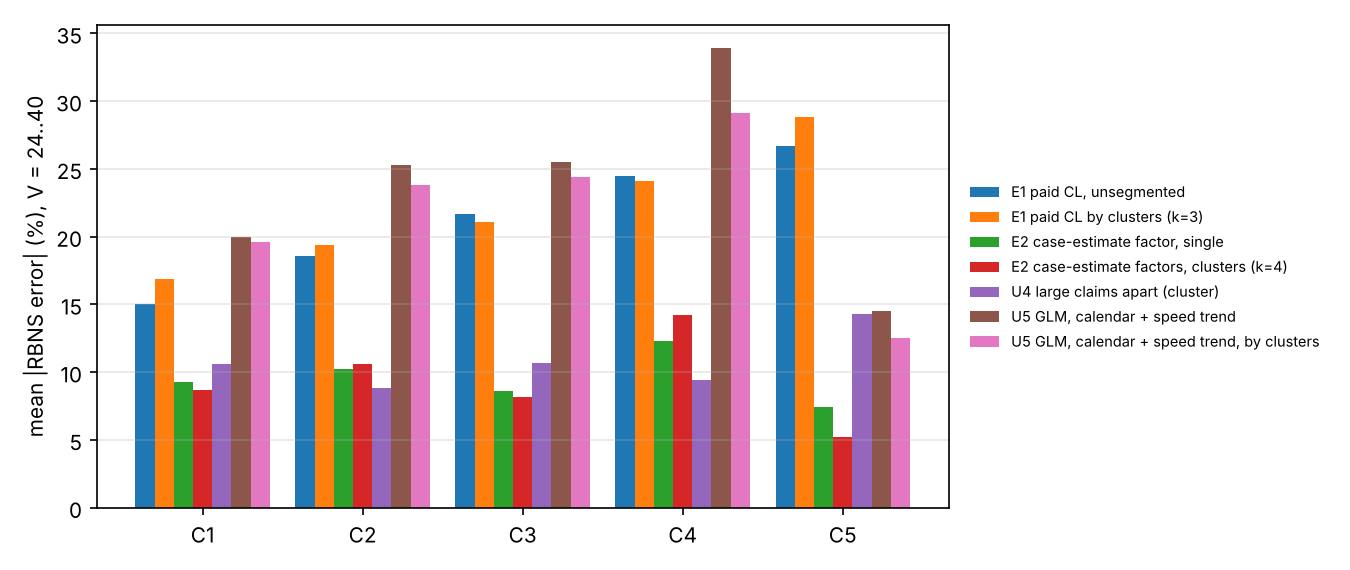

In [3]:
display(Image(str(F / "group_uses_by_scenario.png")))

## 2. Error by valuation date (detail)

In [4]:
bt = pd.read_csv(T / "group_uses_backtest.csv")
bt.pivot_table(index=["scenario", "method"], columns="V", values="error_pct").round(1)

V                                                       24    28    32    36    40
scenario method                                                                   
1        E1 paid CL by clusters (k=3)                -45.1 -16.6   6.1   1.1  15.7
         E1 paid CL by random groups (mean)          -42.2 -17.5   9.1   0.8   6.0
         E1 paid CL, unsegmented                     -42.9 -18.0   8.2   0.5   5.6
         E2 case-estimate factor, single               8.7  -7.3  -6.5 -11.7 -12.3
         E2 case-estimate factors, bands              -3.4 -10.9  -6.1  -8.6 -13.4
...                                                    ...   ...   ...   ...   ...
5        U5 GLM, calendar + speed trend              -23.1 -22.2 -10.4  10.1  -6.8
         U5 GLM, calendar + speed trend, by clusters -18.8 -17.8  -4.6  16.8  -4.8
         U5 GLM, calendar trend                      -14.6  -4.0  14.3  45.7  27.0
         U5 GLM, calendar trend, by clusters         -13.7  -1.9  19.6  51.8  28.0
         U5 GLM, no calendar trend                   -48.7 -41.4 -28.0 -12.2 -24.7

[70 rows x 5 columns]

## 3. Monitoring: mix and settlement speed by cohort and group (V = 40)\n\nSpearman correlation with the notification period; cohorts up to period 32, for which settlement within 8 quarters is observable.

In [5]:
pd.read_csv(T / "group_uses_monitor_trends.csv").round(3)

,scenario,group,mean share,trend in share (Spearman),p-value share,"share settled within 8q, periods 1-10","share settled within 8q, periods 23-32",trend in speed (Spearman),p-value speed
0,1,0,0.456,-0.215,0.182,0.424,0.450,0.110,0.550
1,1,1,0.342,0.142,0.388,0.399,0.464,0.132,0.479
2,1,2,0.210,0.044,0.787,0.087,0.139,0.242,0.182
3,2,0,0.372,0.071,0.672,0.514,0.551,0.207,0.272
4,2,1,0.429,-0.228,0.157,0.307,0.379,0.329,0.066
5,2,2,0.223,-0.017,0.919,0.096,0.133,0.248,0.179
6,3,0,0.374,0.036,0.830,0.509,0.582,0.354,0.055
7,3,1,0.441,-0.190,0.241,0.310,0.383,0.308,0.086
8,3,2,0.209,-0.060,0.718,0.092,0.112,0.262,0.155
9,4,0,0.374,-0.005,0.976,0.504,0.563,0.308,0.098


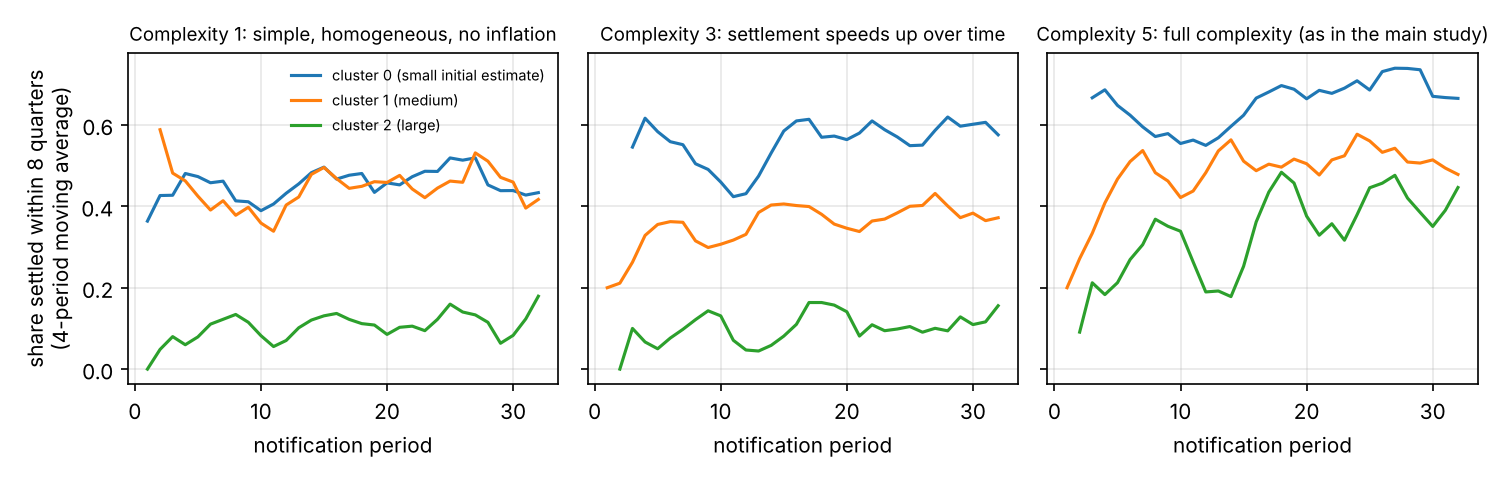

In [6]:
display(Image(str(F / "group_uses_monitor_speed.png")))

## 4. Conclusions

- **Splitting the triangle fails in every scenario,** even without calendar trends (C1, C2). Clusters are never better than random groups.
- **Case-estimate factors are the best approach in C1, C3 and C5** (7–12% error with a single factor). Groups do not improve them on average, and simple bands do as well as clusters.
- **Large claims apart** is the best approach in C2 and C4 (inflation shock): 9% against 24% for paid CL. A simple threshold rule works as well as the cluster.
- **Groups help inside a GLM with calendar and speed trends** (mean 21.9% against 23.8%). This is the one place where clusters add value consistently. Even so, the GLM does not beat the case-estimate factors.
- **Monitoring** gives no false alarm in C1. In C5 it detects a speed-up within the groups, which explains why splitting cannot help. In C3 the signal is weak with 30 cohorts.